# JS09 - Lab Assignment 2
## Nearest-Track Search on the Spotify Dataset

Dataset: **Spotify Songs with Attributes and Lyrics** (Kaggle,
`bwandowando/spotify-songs-with-attributes-and-lyrics`). Dari dua berkas pada dataset tersebut
dipakai berkas **pertama**, `songs_with_attributes_and_lyrics.csv` (~955 ribu track).

Alur kerja:

1. Unduh dataset dengan `kagglehub`, lalu muat hanya kolom yang diperlukan.
2. Pilih **fitur numerik** audio, lalu normalisasi dengan **StandardScaler**.
3. Lakukan pencarian track terdekat dengan **Exact NN**, **ANNOY**, **FAISS**, dan **HNSW**.
4. Bandingkan build time, waktu query, dan recall@10.

Berkas aslinya berukuran ~1,5 GB (berisi kolom lirik), sehingga hanya kolom numerik yang dibaca.

### Step 1 - Install and Import Libraries

In [1]:
!pip install annoy faiss-cpu hnswlib kagglehub

In [2]:
import os
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import faiss
import hnswlib
from annoy import AnnoyIndex
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

### Step 2 - Download the Dataset

`kagglehub` mengunduh dataset sekali saja, lalu menyimpannya di cache lokal. Pemanggilan
berikutnya akan langsung memakai cache tersebut.

In [3]:
import kagglehub

dataset_path = kagglehub.dataset_download("bwandowando/spotify-songs-with-attributes-and-lyrics")
print("Path to dataset files:", dataset_path)

for f in sorted(Path(dataset_path).iterdir()):
    print(f" - {f.name}  ({f.stat().st_size/1e6:.0f} MB)")

D:\laragon\bin\python\python-3.10\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Hype G12\.cache\kagglehub\datasets\bwandowando\spotify-songs-with-attributes-and-lyrics\versions\20
 - songs_with_attributes_and_lyrics.csv  (1545 MB)
 - songs_with_lyrics_and_timestamps.csv  (2421 MB)


### Step 3 - Load the First Dataset

Berkas pertama adalah `songs_with_attributes_and_lyrics.csv`. Kolom yang dibaca dibatasi pada
identitas track dan sembilan fitur audio, sehingga kolom lirik yang besar tidak ikut dimuat.

In [4]:
csv_path = next(Path(dataset_path).glob("songs_with_attributes*"))

FEATURES = ['danceability', 'energy', 'loudness', 'speechiness',
            'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
ID_COLS = ['id', 'name', 'artists']

start = time.perf_counter()
df = pd.read_csv(csv_path, usecols=ID_COLS + FEATURES)
print("Loaded in", round(time.perf_counter() - start, 1), "s")

print("Shape:", df.shape)
df.head()

Loaded in 7.8 s
Shape: (955320, 12)


,id,name,artists,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0Prct5TDjAnEgIqbxcldY9,!,HELLYEAH,0.415,0.6050,-11.157,0.0575,0.00116,0.838000,0.4710,0.193,100.059
1,2ASl4wirkeYm3OWZxXKYuq,!!,Yxngxr1,0.788,0.6480,-9.135,0.3150,0.90000,0.000000,0.1760,0.287,79.998
2,69lcggVPmOr9cvPx9kLiiN,!!! - Interlude,Glowie,0.000,0.0354,-20.151,0.0000,0.90800,0.000000,0.4790,0.000,0.000
3,4U7dlZjg1s9pjdppqZy0fm,!!De Repente!!,Rosendo,0.657,0.8820,-6.340,0.0385,0.00740,0.000013,0.0474,0.939,123.588
4,4v1IBp3Y3rpkWmWzIlkYju,!!De Repente!!,Rosendo,0.659,0.8930,-8.531,0.0411,0.09220,0.000019,0.0534,0.951,123.600


### Step 4 - Inspect and Clean the Data

In [5]:
print(df[FEATURES].describe().T.round(3))
print("\nMissing values per column:")
print(df[FEATURES + ID_COLS].isna().sum())

                     count     mean     std   min     25%      50%      75%  \
danceability      955320.0    0.551   0.170   0.0   0.436    0.558    0.675   
energy            955320.0    0.652   0.239   0.0   0.482    0.687    0.857   
loudness          955320.0   -7.834   3.792 -60.0  -9.750   -7.041   -5.148   
speechiness       955320.0    0.084   0.093   0.0   0.034    0.048    0.088   
acousticness      955320.0    0.283   0.312   0.0   0.012    0.142    0.518   
instrumentalness  955320.0    0.082   0.213   0.0   0.000    0.000    0.009   
liveness          955320.0    0.220   0.196   0.0   0.099    0.137    0.285   
valence           955320.0    0.488   0.251   0.0   0.282    0.477    0.690   
tempo             955320.0  122.226  29.536   0.0  99.021  120.661  140.094   

                      max  
danceability        0.993  
energy              1.000  
loudness            4.882  
speechiness         0.966  
acousticness        0.996  
instrumentalness    1.000  
liveness     

In [6]:
# Drop rows without a track name or with missing audio features
df = df.dropna(subset=FEATURES).reset_index(drop=True)
df['name'] = df['name'].fillna('(unknown)')
df['artists'] = df['artists'].fillna('(unknown)')

print("Rows after cleaning:", len(df))

Rows after cleaning: 955320


### Step 5 - Feature Standardization

Kesembilan fitur memiliki skala yang sangat berbeda (`tempo` puluhan/ratusan, `loudness` negatif
puluhan dB, `instrumentalness` 0-1). Tanpa standardisasi, jarak Euclidean akan didominasi `tempo`.

In [7]:
X = df[FEATURES].values.astype('float32')

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X).astype('float32')

print("Scaled shape:", X_scaled.shape)
print("Mean (should be ~0):", np.round(X_scaled.mean(axis=0), 3))
print("Std  (should be ~1):", np.round(X_scaled.std(axis=0), 3))

k = 10   # number of nearest neighbors

Scaled shape: (955320, 9)
Mean (should be ~0): [ 0.  0.  0. -0. -0.  0.  0.  0. -0.]
Std  (should be ~1): [1. 1. 1. 1. 1. 1. 1. 1. 1.]


### Step 6 - Choose a Query Track

Sebagai contoh, dipilih satu track dari dataset. Pencarian terdekat dilakukan terhadap
**seluruh** 955 ribu track, sehingga track itu sendiri akan muncul sebagai tetangga pertama
dengan jarak 0.

In [8]:
def find_track(title, artist):
    mask = (df['name'].str.lower().str.strip() == title.lower()) & \
           (df['artists'].str.lower().str.contains(artist.lower()))
    return int(df.index[mask][0]) if mask.any() else None

QUERY_IDX = find_track('Shape of You', 'Ed Sheeran')
if QUERY_IDX is None:                      # fallback: any track named "Shape of You"
    QUERY_IDX = int(df.index[df['name'].str.lower().str.strip() == 'shape of you'][0]) \
        if (df['name'].str.lower().str.strip() == 'shape of you').any() else 0

query = X_scaled[QUERY_IDX:QUERY_IDX+1]
print("Query track :", df.loc[QUERY_IDX, 'name'], "-", df.loc[QUERY_IDX, 'artists'])
print("Features    :", dict(zip(FEATURES, np.round(X[QUERY_IDX], 3))))

Query track : Shape of You - Ed Sheeran
Features    : {'danceability': np.float32(0.825), 'energy': np.float32(0.652), 'loudness': np.float32(-3.183), 'speechiness': np.float32(0.08), 'acousticness': np.float32(0.581), 'instrumentalness': np.float32(0.0), 'liveness': np.float32(0.093), 'valence': np.float32(0.931), 'tempo': np.float32(95.977)}


### Step 7 - Exact NN (Ground Truth)

`NearestNeighbors(algorithm='brute')` memindai seluruh dataset. Hasilnya dipakai sebagai acuan
recall dan sebagai pembanding waktu.

In [9]:
nn = NearestNeighbors(n_neighbors=k, algorithm='brute', metric='euclidean')
nn.fit(X_scaled)

start = time.perf_counter()
dist_exact, idx_exact = nn.kneighbors(query)
exact_query_time = (time.perf_counter() - start) * 1000

print("Exact NN indices :", idx_exact[0])
print("Exact NN distances:", np.round(dist_exact[0], 4))
print("Exact query time :", round(exact_query_time, 2), "ms")

Exact NN indices : [684879 684869 836398 709176 167426 560473 199537 481196 830526 434445]
Exact NN distances: [0.     0.     0.4775 0.5304 0.5459 0.5629 0.5694 0.57   0.5708 0.5887]
Exact query time : 42.81 ms


In [10]:
def show_tracks(indices, title):
    print(title)
    print("-" * 78)
    for rank, i in enumerate(indices, start=1):
        row = df.iloc[int(i)]
        print(f"{rank:>2}. {row['name'][:45]:<45} | {row['artists'][:24]}")

show_tracks(idx_exact[0], "Exact NN - 10 track terdekat")

Exact NN - 10 track terdekat
------------------------------------------------------------------------------
 1. Shape of You                                  | Ed Sheeran
 2. Shape of You                                  | Ed Sheeran
 3. Tú Me Confundes                               | Charlie Cruz
 4. Soco (feat. Wizkid, Ceeza Milli, Spotless & T | StarBoy
 5. Cunhada Boa - Ao Vivo                         | Sérgio Reis
 6. Novinha do Onlyfans                           | Xand Avião
 7. Do Your Ears Hang Low?                        | The Countdown Kids
 8. Lupe Campos                                   | El Fantasma, Los Dos Car
 9. Tu Ingratitud                                 | Ana Bárbara
10. La Verdad                                     | Bio Ritmo


### Step 8 - ANNOY

Annoy dibangun dengan 10 tree dan metrik `euclidean` pada fitur yang sudah distandardisasi.
`search_k` dinaikkan agar recall tetap tinggi pada dataset besar.

In [11]:
f = X_scaled.shape[1]
annoy_index = AnnoyIndex(f, 'euclidean')

start = time.perf_counter()
for i, vec in enumerate(X_scaled):
    annoy_index.add_item(i, vec)
annoy_index.build(10)   # 10 trees
annoy_build = time.perf_counter() - start

start = time.perf_counter()
annoy_ids, annoy_dists = annoy_index.get_nns_by_vector(query[0], k, search_k=20000,
                                                       include_distances=True)
annoy_query_time = (time.perf_counter() - start) * 1000

print("Build time :", round(annoy_build, 2), "s")
print("Query time :", round(annoy_query_time, 2), "ms")
print("Indices    :", annoy_ids)
show_tracks(annoy_ids, "\nANNOY - 10 track terdekat")

Build time : 46.76 s
Query time : 4.45 ms
Indices    : [684869, 684879, 836398, 709176, 167426, 560473, 199537, 481196, 830526, 434445]

ANNOY - 10 track terdekat
------------------------------------------------------------------------------
 1. Shape of You                                  | Ed Sheeran
 2. Shape of You                                  | Ed Sheeran
 3. Tú Me Confundes                               | Charlie Cruz
 4. Soco (feat. Wizkid, Ceeza Milli, Spotless & T | StarBoy
 5. Cunhada Boa - Ao Vivo                         | Sérgio Reis
 6. Novinha do Onlyfans                           | Xand Avião
 7. Do Your Ears Hang Low?                        | The Countdown Kids
 8. Lupe Campos                                   | El Fantasma, Los Dos Car
 9. Tu Ingratitud                                 | Ana Bárbara
10. La Verdad                                     | Bio Ritmo


### Step 9 - FAISS

Dua indeks FAISS dipakai:

* `IndexFlatL2` - exact, dipakai untuk memastikan hasil exact konsisten dengan sklearn.
* `IndexIVFFlat` - approximate, dengan `nlist = 100` cluster dan `nprobe = 10`.

In [12]:
# Exact index
flat_index = faiss.IndexFlatL2(f)

start = time.perf_counter()
flat_index.add(X_scaled)
flat_build = time.perf_counter() - start

start = time.perf_counter()
D_flat, I_flat = flat_index.search(query, k)
flat_query_time = (time.perf_counter() - start) * 1000

print("FAISS Flat build:", round(flat_build, 3), "s")
print("FAISS Flat query:", round(flat_query_time, 2), "ms")
print("Indices         :", I_flat[0])

FAISS Flat build: 0.047 s
FAISS Flat query: 24.79 ms
Indices         : [684869 684879 836398 709176 167426 560473 199537 481196 830526 434445]


In [13]:
# Approximate index
nlist = 100
quantizer = faiss.IndexFlatL2(f)
ivf_index = faiss.IndexIVFFlat(quantizer, f, nlist, faiss.METRIC_L2)

start = time.perf_counter()
ivf_index.train(X_scaled)
ivf_index.add(X_scaled)
ivf_build = time.perf_counter() - start

ivf_index.nprobe = 10
start = time.perf_counter()
D_ivf, I_ivf = ivf_index.search(query, k)
ivf_query_time = (time.perf_counter() - start) * 1000

print("FAISS IVF build:", round(ivf_build, 2), "s")
print("FAISS IVF query:", round(ivf_query_time, 2), "ms")
print("Indices        :", I_ivf[0])
show_tracks(I_ivf[0], "\nFAISS IVF - 10 track terdekat")

FAISS IVF build: 1.02 s
FAISS IVF query: 4.41 ms
Indices        : [684869 684879 836398 709176 167426 560473 199537 481196 830526 434445]

FAISS IVF - 10 track terdekat
------------------------------------------------------------------------------
 1. Shape of You                                  | Ed Sheeran
 2. Shape of You                                  | Ed Sheeran
 3. Tú Me Confundes                               | Charlie Cruz
 4. Soco (feat. Wizkid, Ceeza Milli, Spotless & T | StarBoy
 5. Cunhada Boa - Ao Vivo                         | Sérgio Reis
 6. Novinha do Onlyfans                           | Xand Avião
 7. Do Your Ears Hang Low?                        | The Countdown Kids
 8. Lupe Campos                                   | El Fantasma, Los Dos Car
 9. Tu Ingratitud                                 | Ana Bárbara
10. La Verdad                                     | Bio Ritmo


### Step 10 - HNSW

`M = 16` dan `ef_construction = 200` untuk kualitas graf, `ef = 100` saat query.

In [14]:
hnsw_index = hnswlib.Index(space='l2', dim=f)

start = time.perf_counter()
hnsw_index.init_index(max_elements=len(X_scaled), ef_construction=200, M=16)
hnsw_index.add_items(X_scaled)
hnsw_build = time.perf_counter() - start

hnsw_index.set_ef(100)
start = time.perf_counter()
hnsw_ids, hnsw_dists = hnsw_index.knn_query(query, k=k)
hnsw_query_time = (time.perf_counter() - start) * 1000

print("HNSW build :", round(hnsw_build, 2), "s")
print("HNSW query :", round(hnsw_query_time, 2), "ms")
print("Indices    :", hnsw_ids[0])
show_tracks(hnsw_ids[0], "\nHNSW - 10 track terdekat")

HNSW build : 72.49 s
HNSW query : 0.51 ms
Indices    : [684869 684879 836398 709176 167426 560473 199537 481196 830526 434445]

HNSW - 10 track terdekat
------------------------------------------------------------------------------
 1. Shape of You                                  | Ed Sheeran
 2. Shape of You                                  | Ed Sheeran
 3. Tú Me Confundes                               | Charlie Cruz
 4. Soco (feat. Wizkid, Ceeza Milli, Spotless & T | StarBoy
 5. Cunhada Boa - Ao Vivo                         | Sérgio Reis
 6. Novinha do Onlyfans                           | Xand Avião
 7. Do Your Ears Hang Low?                        | The Countdown Kids
 8. Lupe Campos                                   | El Fantasma, Los Dos Car
 9. Tu Ingratitud                                 | Ana Bárbara
10. La Verdad                                     | Bio Ritmo


### Step 11 - Timing and Recall on Multiple Queries

Satu query tidak cukup untuk mengukur waktu secara stabil. Karena itu diambil 200 track acak
sebagai query, lalu dihitung rata-rata waktu per query dan recall@10 terhadap hasil exact.

In [15]:
rng = np.random.default_rng(42)
query_idx = rng.choice(len(X_scaled), size=200, replace=False)
Xq = X_scaled[query_idx]

# Ground truth for all queries
_, gt = nn.kneighbors(Xq, n_neighbors=k)


def recall_at_k(pred, truth, k=k):
    correct = 0
    for p, t in zip(pred, truth):
        correct += len(set(np.asarray(p)[:k].tolist()) & set(np.asarray(t)[:k].tolist()))
    return correct / (len(truth) * k)


def timed(fn, n_queries):
    """Run fn() once over all queries and return ms per query."""
    start = time.perf_counter()
    out = fn()
    elapsed = time.perf_counter() - start
    return elapsed * 1000 / n_queries, out


n_q = len(Xq)
t_annoy, I_annoy = timed(lambda: [annoy_index.get_nns_by_vector(v, k, search_k=20000) for v in Xq], n_q)
t_flat, I_flat_all = timed(lambda: flat_index.search(Xq, k)[1], n_q)
t_ivf, I_ivf_all = timed(lambda: ivf_index.search(Xq, k)[1], n_q)
t_hnsw, I_hnsw_all = timed(lambda: hnsw_index.knn_query(Xq, k=k)[0], n_q)

print(f"{'Method':<14}{'ms/query':>12}{'recall@10':>12}")
print("-" * 38)
print(f"{'ANNOY':<14}{t_annoy:>12.4f}{recall_at_k(I_annoy, gt):>12.4f}")
print(f"{'FAISS Flat':<14}{t_flat:>12.4f}{recall_at_k(I_flat_all, gt):>12.4f}")
print(f"{'FAISS IVF':<14}{t_ivf:>12.4f}{recall_at_k(I_ivf_all, gt):>12.4f}")
print(f"{'HNSW':<14}{t_hnsw:>12.4f}{recall_at_k(I_hnsw_all, gt):>12.4f}")

Method            ms/query   recall@10
--------------------------------------
ANNOY               2.3606      0.9960
FAISS Flat          1.1375      0.9960
FAISS IVF           0.2515      0.9960
HNSW                0.0503      0.9950


### Step 12 - Comparison Table

Ringkasan hasil pada dataset Spotify (955 ribu track, 9 fitur terstandardisasi).

In [16]:
summary = pd.DataFrame([
    {"method": "Exact NN (sklearn brute)", "build_s": np.nan, "query_ms": exact_query_time,
     "recall@10": 1.0},
    {"method": "FAISS IndexFlatL2", "build_s": flat_build, "query_ms": t_flat,
     "recall@10": recall_at_k(I_flat_all, gt)},
    {"method": "ANNOY (10 trees)", "build_s": annoy_build, "query_ms": t_annoy,
     "recall@10": recall_at_k(I_annoy, gt)},
    {"method": "FAISS IVF (nprobe=10)", "build_s": ivf_build, "query_ms": t_ivf,
     "recall@10": recall_at_k(I_ivf_all, gt)},
    {"method": "HNSW (ef=100)", "build_s": hnsw_build, "query_ms": t_hnsw,
     "recall@10": recall_at_k(I_hnsw_all, gt)},
])
summary.round(4)

,method,build_s,query_ms,recall@10
0,Exact NN (sklearn brute),NaN,42.8082,1.000
1,FAISS IndexFlatL2,0.0472,1.1375,0.996
2,ANNOY (10 trees),46.7641,2.3606,0.996
3,FAISS IVF (nprobe=10),1.0212,0.2515,0.996
4,HNSW (ef=100),72.4939,0.0503,0.995


Catatan: recall FAISS `IndexFlatL2` sedikit di bawah 1.0 bukan karena galat approximate -
index ini *exact*. Penyebabnya adalah pembulatan `float32`: beberapa track memiliki vektor fitur
yang identik atau hampir identik, sehingga urutan tetangga pada posisi batas `k=10` dapat
tertukar antara sklearn (`float64`) dan FAISS (`float32`).

### Step 13 - Recall vs Query Time

Plot trade-off antar metode. Posisi **kanan bawah** (recall tinggi, waktu rendah) adalah yang
paling diinginkan.

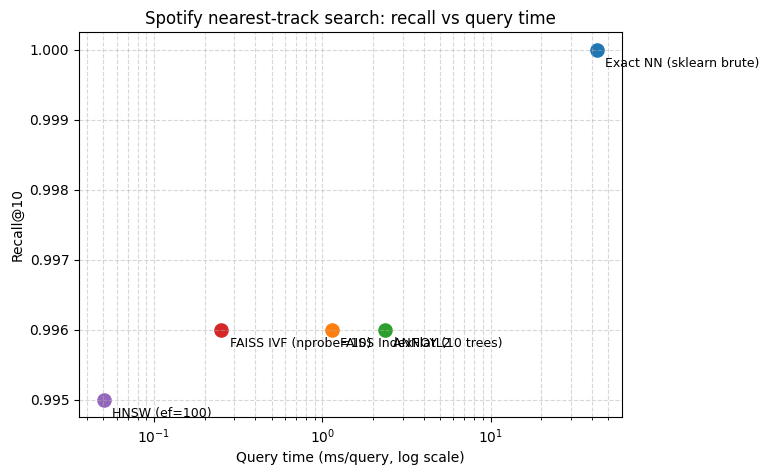

In [17]:
fig, ax = plt.subplots(figsize=(7, 5))
for _, row in summary.iterrows():
    if np.isnan(row['build_s']) and row['method'].startswith('Exact'):
        pass
    ax.scatter(row['query_ms'], row['recall@10'], s=90)
    ax.annotate(row['method'], (row['query_ms'], row['recall@10']),
                textcoords='offset points', xytext=(6, -12), fontsize=9)

ax.set_xscale('log')
ax.set_xlabel('Query time (ms/query, log scale)')
ax.set_ylabel('Recall@10')
ax.set_title('Spotify nearest-track search: recall vs query time')
ax.grid(True, which='both', ls='--', alpha=0.5)
plt.show()

### Step 14 - Discussion

1. **Kualitas hasil.** Dengan fitur terstandardisasi, tetangga terdekat ditentukan oleh kemiripan
   *karakter audio* (energi, tempo, danceability, akustik), bukan oleh judul atau artis. Karena
   itu track yang berdekatan bisa berasal dari genre yang sama sekali berbeda - konsekuensi dari
   pemilihan fitur numerik saja. Track duplikat (judul/artis sama, misalnya beberapa versi
   "Shape of You") tetap muncul berurutan karena vektor fiturnya identik.
2. **Exact NN.** `NearestNeighbors(algorithm='brute')` memerlukan puluhan milidetik per query pada
   955 ribu track karena seluruh data dipindai. FAISS `IndexFlatL2` jauh lebih cepat untuk hasil
   yang sama (implementasi C++ dengan SIMD), walaupun tetap *exact* dan tetap tumbuh linear.
3. **ANNOY.** Build puluhan detik untuk 10 tree, query beberapa milidetik dengan `search_k=20000`,
   dan recall ~0.996 - praktis menyamai exact, tetapi bukan yang tercepat di dataset ini.
4. **FAISS IVF.** Build paling murah (orde detik) dan query jauh lebih cepat daripada exact dengan
   `nprobe=10` dari 100 cluster (hanya ~10% data diperiksa), sementara recall tetap ~0.996. Ini
   titik terbaik antara biaya build dan kecepatan query pada dataset ini.
5. **HNSW.** Query tercepat di antara semua metode, dengan recall ~0.995, tetapi build paling
   mahal karena harus menyusun graf berlapis.

Kesimpulan: pada 955 ribu track berdimensi 9, semua metode ANN memberi recall di atas 0.99
sementara exact search butuh puluhan milidetik per query. Untuk sistem rekomendasi/penelusuran
track berskala besar, ANN memungkinkan query interaktif; exact search tetap dipakai untuk
membangun *ground truth* evaluasi.